# 07 · Comparativa de RNN, LSTM y GRU en el test

**Objetivo:** comparar las tres redes entre sí y con los modelos de referencia en el periodo de test (2024-2026), que **no se ha usado para nada antes**, y elegir el modelo que se integra en la aplicación.

Protocolo (`scripts/train.py`):
1. Para cada red y horizonte se toma la mejor configuración del ajuste walk-forward (notebook 06).
2. Se entrena con todos los datos anteriores a 2024 (respetando el embargo de *h* días y la misma regla de parada temprana).
3. Se repite con **5 semillas** distintas: la media de sus predicciones es la predicción final (*ensemble*) y su dispersión mide la **estabilidad**.
4. El tiempo de entrenamiento se mide en las mismas condiciones para todas (CPU, 1 hilo).

```bash
poetry run python scripts/train.py
```

> **Cómo leer las fechas del test:** el origen de la predicción va de enero de 2024 al último día con objetivo conocido. A 252 días, el último origen es de noviembre de 2025 y su objetivo cae en noviembre de 2026; por eso el test de largo plazo tiene menos observaciones.

> **Nota:** este notebook documenta el **primer test (ronda 1)**, con las ganadoras de la ronda 1 (`reports/results/ronda_1/`). Las rondas posteriores y el segundo test están en el notebook 08 (registro de experimentos). La comparativa final se rehará con el modelo definitivo.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from oil_forecast.config import HORIZONS, results_dir

RESULTS_DIR = results_dir(1)  # first test, with the round-1 winners
from oil_forecast.plotting import COLORS, LINESTYLES, set_style

set_style()
pd.set_option("display.float_format", "{:.2f}".format)

comp = pd.read_csv(RESULTS_DIR / "comparativa.csv")
seeds = pd.read_csv(RESULTS_DIR / "metricas_por_semilla.csv")
preds = pd.read_csv(RESULTS_DIR / "predicciones_test.csv", parse_dates=["origen", "fecha_objetivo"])
NETS = ["RNN simple", "LSTM", "GRU"]
BASE = ["Ingenuo", "Media histórica", "Ridge"]

## 1. Tabla comparativa (requisito del enunciado)

Para cada red y horizonte: MAE, RMSE, mejora frente al ingenuo, número de parámetros y tiempo de entrenamiento. Se añaden MSE, acierto direccional, la significación de la mejora (Diebold-Mariano) y la variabilidad entre semillas.

In [2]:
table = comp.assign(
    **{"Mejora RMSE %": comp["Mejora_RMSE_vs_ingenuo_%"], "Mejora MAE %": comp["Mejora_MAE_vs_ingenuo_%"],
       "Dirección %": comp["Direccion_%"], "p-valor DM": comp["DM_p_valor"],
       "Parámetros": comp["n_params"], "Tiempo (s)": comp["tiempo_entrenamiento_s"],
       "Desv. mejora entre semillas": comp["Mejora_RMSE_desv_semillas"]}
)[["horizonte", "modelo", "MAE", "RMSE", "MSE", "Mejora RMSE %", "Mejora MAE %", "Dirección %", "p-valor DM",
   "Parámetros", "Tiempo (s)", "Desv. mejora entre semillas"]]
table["horizonte"] = pd.Categorical(table["horizonte"], list(HORIZONS), ordered=True)
table = table.sort_values(["horizonte"], kind="stable").set_index(["horizonte", "modelo"])
table.style.format(precision=2, na_rep="—").background_gradient(subset=["Mejora RMSE %"], cmap="RdYlGn", vmin=-10, vmax=10)

## 2. Mejora frente al ingenuo y estabilidad entre semillas

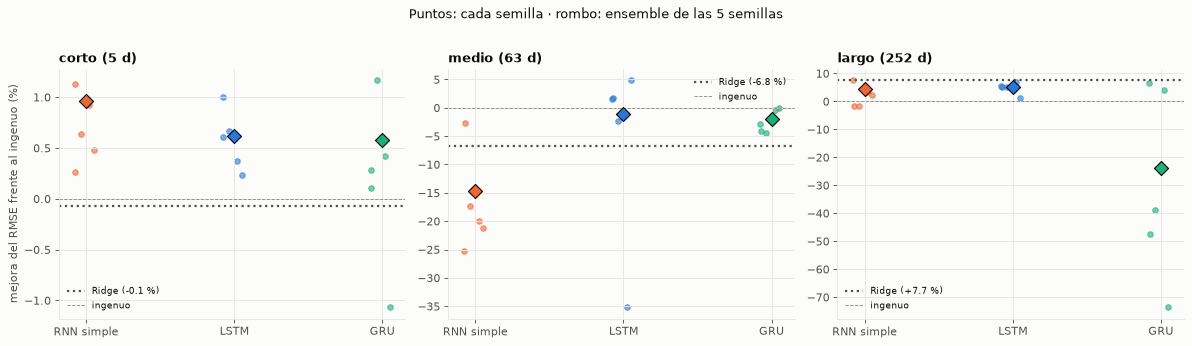

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, hname in zip(axes, HORIZONS):
    s = seeds[seeds.horizonte == hname]
    for i, net in enumerate(NETS):
        vals = s.loc[s.modelo == net, "Mejora_RMSE_vs_ingenuo_%"]
        ax.scatter(np.full(len(vals), i) + np.random.default_rng(0).uniform(-0.08, 0.08, len(vals)), vals,
                   color=COLORS[net], alpha=0.6, s=25)
        ens = comp.loc[(comp.horizonte == hname) & (comp.modelo == net), "Mejora_RMSE_vs_ingenuo_%"].item()
        ax.scatter(i, ens, marker="D", s=80, color=COLORS[net], edgecolor="k", zorder=3)
    ridge = comp.loc[(comp.horizonte == hname) & (comp.modelo == "Ridge"), "Mejora_RMSE_vs_ingenuo_%"].item()
    ax.axhline(ridge, color=COLORS["Ridge"], ls=":", label=f"Ridge ({ridge:+.1f} %)")
    ax.axhline(0, color=COLORS["Ingenuo"], ls="--", lw=0.8, label="ingenuo")
    ax.set_xticks(range(3), NETS); ax.set_title(f"{hname} ({HORIZONS[hname]} d)"); ax.legend(fontsize=8)
axes[0].set_ylabel("mejora del RMSE frente al ingenuo (%)")
fig.suptitle("Puntos: cada semilla · rombo: ensemble de las 5 semillas", y=1.02)
plt.tight_layout()

## 3. Predicciones frente a la realidad

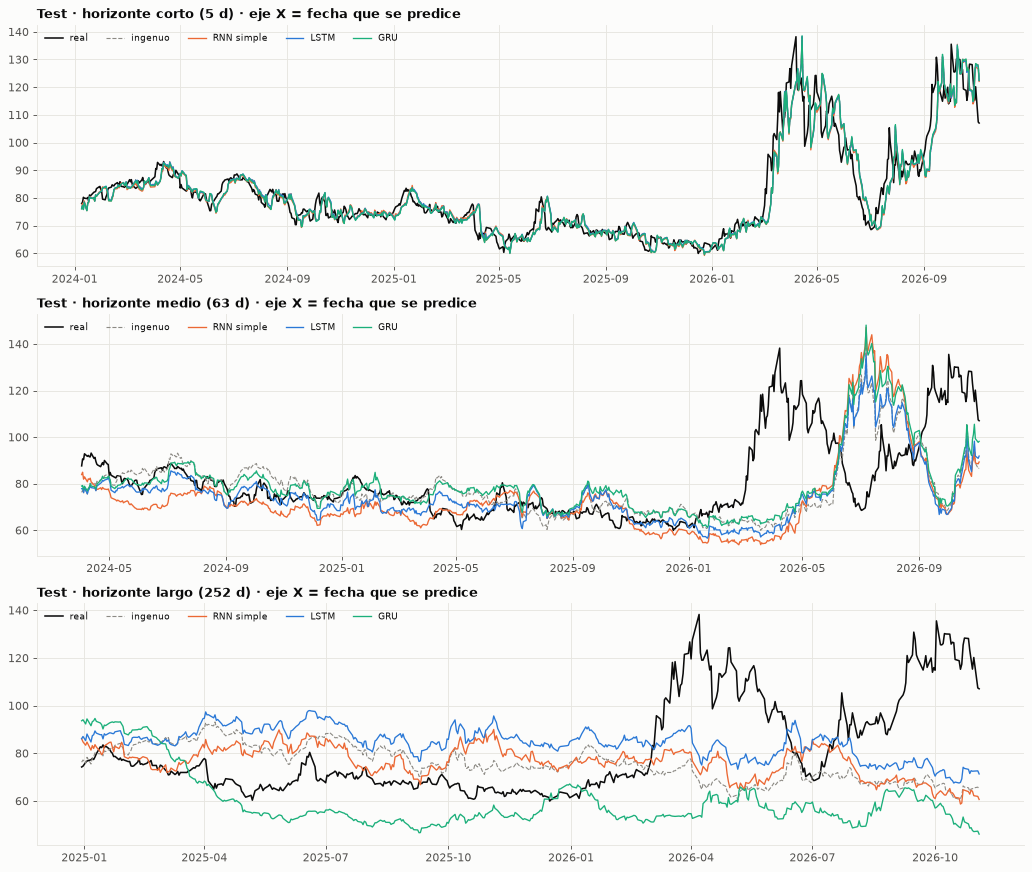

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11))
for ax, hname in zip(axes, HORIZONS):
    p = preds[preds.horizonte == hname]
    real = p[p.modelo == "Ingenuo"].set_index("fecha_objetivo")
    ax.plot(real.index, real["precio_real"], color=COLORS["Real"], lw=1.4, label="real")
    ax.plot(real.index, real["precio_pred"], color=COLORS["Ingenuo"], ls=LINESTYLES["Ingenuo"], lw=1, label="ingenuo")
    for net in NETS:
        q = p[p.modelo == net].set_index("fecha_objetivo")
        ax.plot(q.index, q["precio_pred"], color=COLORS[net], lw=1.2, label=net)
    ax.set_title(f"Test · horizonte {hname} ({HORIZONS[hname]} d) · eje X = fecha que se predice")
    ax.legend(fontsize=8, ncol=5, loc="upper left")
plt.tight_layout()

## 4. ¿Dónde gana y dónde pierde cada red?

Diferencia acumulada de errores al cuadrado frente al ingenuo: si la curva **sube**, la red va acumulando ventaja; si **baja**, el ingenuo acierta más en ese periodo. Permite ver qué episodios deciden el resultado.

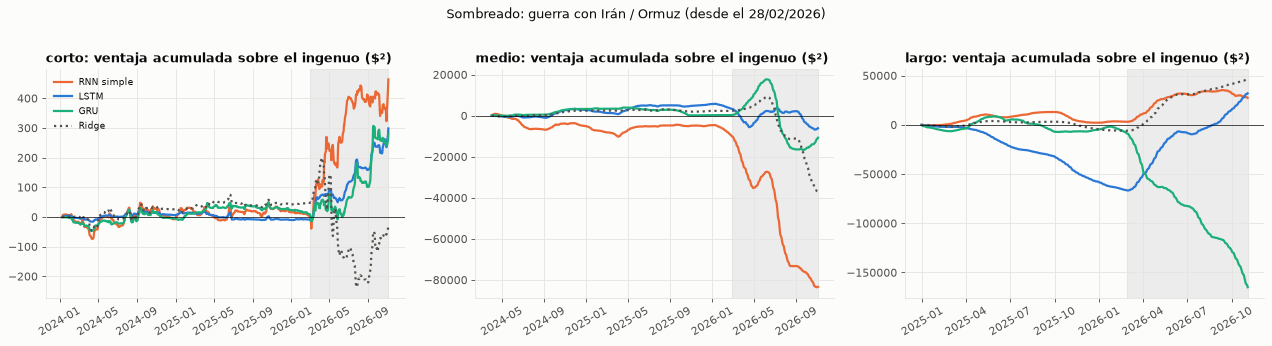

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, hname in zip(axes, HORIZONS):
    p = preds[preds.horizonte == hname]
    naive = p[p.modelo == "Ingenuo"].set_index("fecha_objetivo")
    e_naive = (naive["precio_real"] - naive["precio_pred"]) ** 2
    for net in NETS + ["Ridge"]:
        q = p[p.modelo == net].set_index("fecha_objetivo")
        ax.plot(q.index, (e_naive - (q["precio_real"] - q["precio_pred"]) ** 2).cumsum(), color=COLORS[net], label=net,
                ls=":" if net == "Ridge" else "-")
    ax.axhline(0, color="k", lw=0.6)
    ax.axvspan(pd.Timestamp("2026-02-28"), naive.index.max(), color="grey", alpha=0.12)
    ax.set_title(f"{hname}: ventaja acumulada sobre el ingenuo ($²)"); ax.tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8)
fig.suptitle("Sombreado: guerra con Irán / Ormuz (desde el 28/02/2026)", y=1.02)
plt.tight_layout()

In [6]:
p = preds.assign(año=preds["fecha_objetivo"].dt.year)
def by_year(g):
    if len(g) < 20:  # years with only a few predicted dates are not comparable
        return np.nan
    naive = np.sqrt(((g["precio_real"] - g["precio_hoy"]) ** 2).mean())
    return (1 - np.sqrt(((g["precio_real"] - g["precio_pred"]) ** 2).mean()) / naive) * 100
yearly = (p[p.modelo.isin(NETS + ["Ridge"])].groupby(["horizonte", "modelo", "año"])[["precio_real", "precio_pred", "precio_hoy"]]
          .apply(by_year).unstack("año"))
print("Mejora del RMSE frente al ingenuo (%) según el año de la fecha predicha (— = menos de 20 fechas):")
(yearly.loc[list(HORIZONS)].style.format("{:+.1f}", na_rep="—")
 .background_gradient(cmap="RdYlGn", vmin=-25, vmax=25))

Mejora del RMSE frente al ingenuo (%) según el año de la fecha predicha (— = menos de 20 fechas):


## 5. Coste computacional

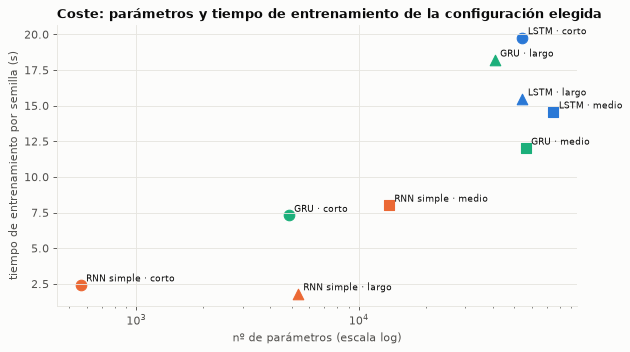

In [7]:
cost = comp[comp.modelo.isin(NETS)]
fig, ax = plt.subplots(figsize=(8, 4.5))
for _, r in cost.iterrows():
    ax.scatter(r["n_params"], r["tiempo_entrenamiento_s"], s=90, color=COLORS[r["modelo"]],
               marker={"corto": "o", "medio": "s", "largo": "^"}[r["horizonte"]])
    ax.annotate(f"{r['modelo']} · {r['horizonte']}", (r["n_params"], r["tiempo_entrenamiento_s"]), xytext=(5, 3),
                textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("nº de parámetros (escala log)"); ax.set_ylabel("tiempo de entrenamiento por semilla (s)")
ax.set_title("Coste: parámetros y tiempo de entrenamiento de la configuración elegida")
plt.tight_layout()

## 6. Lectura de los resultados

**Corto plazo (5 días):** las tres redes mejoran al ingenuo **todas las semillas salvo una**, pero muy poco: el RMSE baja de 5,82 $ a 5,76-5,79 $ (unos 4-6 céntimos). La mejora de la LSTM es **estadísticamente significativa** (Diebold-Mariano p = 0,03) y la más estable entre semillas. La ventaja se acumula casi entera en 2026: con volatilidad extrema, la red anticipa algo mejor los rebotes de muy corto plazo.

**Medio plazo (63 días):** **ninguna red bate al ingenuo en el test**, y la RNN simple, la mejor en validación (0,919), es la peor (−14,7 %): predice caídas de forma sistemática desde 2024. La LSTM sí ganaba con claridad en 2024 (+17 %) y 2025 (+14 %), pero el shock de Ormuz (desde marzo de 2026) borra esa ventaja. Es exactamente el riesgo de cambio de régimen identificado en el EDA (hallazgo H8). Además, a este horizonte la parada temprana se detiene en la 1ª-2ª época en LSTM y GRU, y una de las cinco semillas de la LSTM se desvía mucho (−35 %): señal de que hay poca estructura estable que aprender.

**Largo plazo (252 días):** la LSTM (+5,3 %) y la RNN (+4,5 %) mejoran al ingenuo, y la GRU se hunde (−23,7 %, con una semilla en −74 %). Pero el gráfico de ventaja acumulada muestra que **la mejora de la LSTM no es habilidad**: durante todo 2025 predijo precios más altos de los que hubo (perdía claramente) y fue la guerra de 2026 la que le dio la razón. Con un acierto direccional del 40 % y p = 0,86, no se puede afirmar que aporte valor a un año vista.

**Frente al Ridge:** el modelo lineal con la misma información es mejor a 252 días (+7,7 %) y peor a 63 (−6,8 %). **La recurrencia no aporta de forma consistente** sobre un modelo lineal regularizado: un resultado habitual en series financieras con poca señal, y coherente con la literatura (Alquist, Kilian y Vigfusson, 2013).

## 7. Elección del modelo para la aplicación

| Criterio | RNN simple | LSTM | GRU |
|---|---|---|---|
| Horizontes que mejoran al ingenuo en **validación** | 2 de 3 | **3 de 3** | 2 de 3 |
| Horizontes que mejoran al ingenuo en **test** | 2 de 3 | 2 de 3 | 1 de 3 |
| **Peor resultado en test** (ensemble) | −14,7 % (63 d) | **−1,1 %** (63 d) | −23,7 % (252 d) |
| Mejora significativa (DM p < 0,05) | ninguna | **5 días** | ninguna |
| Estabilidad entre semillas (desv. de la mejora, 5/63/252 d) | 0,3 / 8,7 / 3,8 | 0,3 / 16,6 / 2,1 | 0,8 / 2,1 / 34,6 |
| Coste (parámetros · s por entrenamiento) | 0,6-14 mil · 2-8 s | 54-75 mil · 15-20 s | 5-56 mil · 7-18 s |

**Modelo elegido: LSTM**, con un modelo por horizonte y la media de 5 semillas como predicción.
- **Precisión:** es la única red que mejora al ingenuo en validación en los tres horizontes, y en el test mejora a 5 y 252 días.
- **Robustez:** es la única sin ningún horizonte catastrófico (su peor caso es −1,1 %, frente a −14,7 % y −23,7 %). Para una herramienta de apoyo a decisiones importa más no equivocarse mucho que ganar por poco.
- **Estabilidad:** es la más estable entre semillas a 5 y 252 días; la semilla anómala a 63 días se neutraliza promediando las cinco.
- **Coste:** es la más cara, pero menos de 20 segundos por entrenamiento en CPU es irrelevante para reentrenar periódicamente desde la app.

## 8. ¿En qué horizontes aporta valor?

| Horizonte | ¿Mejora al ingenuo? | Qué debe decir la aplicación |
|---|---|---|
| **5 días** | Sí, de forma significativa, pero mínima (≈ 1 %) | La predicción central es prácticamente el precio actual; lo útil es el **rango de incertidumbre**, que se ensancha con la volatilidad |
| **63 días** | No en el test (sí en periodos tranquilos como 2024-2025) | Orientativa en mercados en calma; **un shock geopolítico la invalida**. Mostrar el rango y los factores de riesgo |
| **252 días** | No de forma fiable (mejora debida al shock de 2026) | Escenario de referencia, no predicción: el rango del 80 % es lo relevante |

**Conclusión:** ninguna red recurrente "predice" el precio del petróleo mejor que el mercado de forma consistente, y así debe venderse con honestidad. El valor de la herramienta está en:
1. dar una predicción **al menos tan buena como la referencia** en todos los horizontes (sin errores catastróficos, a diferencia de RNN y GRU);
2. **cuantificar la incertidumbre** de cada horizonte, que es lo que necesita un comité para cubrir riesgos y planificar compras;
3. **explicar** qué está pasando (régimen de volatilidad, shocks de oferta) y cuándo no fiarse.

**Siguiente paso:** construir los intervalos de incertidumbre del 80 % sobre la LSTM y comprobar su cobertura real en el test.
